<span style="color: #E6E6E6;">
<span style="background-color: #00695C; padding:8px; display:block; border-left:4px solid #4682b4">



# Week 9 - Word Embeddings

Word embeddings is a very popular an effective manner of giving ML models a sort of background knowledge of the vocabulary of a given document corpus. 

A word embedding is effectively, just a learned vector representation for text. The vectors can be in any number of arbitrary dimensions $m$, but the rule of thumb is often, that larger vocabularies and more intricate patterns, require more dimensions. Often, (and in this case) the goal is to have the vector representations model words semantic meanings, so words with similar meaning in texts, have similar representations. An example could be the words "cat" and "mouse" having a small difference between them, when compared to a word such as "prestidigitation".

Two things in particular are cool about word embeddings:

1. They can be used for downstream tasks; if you make a set of word embeddings using one dataset, they can most likely be used for other NLP applications, not even relevant to the original dataset on which the embeddings were trained.
2. They often "naturally" appear in neural networks. The first few layers often create useful representations of words so that similar words have similar representations. This means, these initial neural network layers can be extracted for other downstream applications, something which [Skipgram and CBOW](https://medium.com/@RobuRishabh/learning-word-embeddings-with-cbow-and-skip-gram-b834bde18de4) models leverage.

---

**At the end of this week, you should be able to:**

- Explain what word embeddings are
- Explain what a word co-occurence matrix is
- Know how to compare words using cosine similarities
- Explain hoa  GloVe word-embedding matrix looks roughly
- Explain how word embedding vectors relate to one another for related words.
- Reflect on how word embeddings can transmit societal bias 

---

## GloVE

[GloVe: Gloval Vectors for Word Representations](https://nlp.stanford.edu/projects/glove/) is an unsupervised learning method to obtain vector representations for words. [The paper is available here](https://nlp.stanford.edu/pubs/glove.pdf). The group out of Stanford, have released numerous different models, we will work with one trained on Wikipedia 2014, which contains $400000$ words, each represented by a feature vector with a dimensionality of $50$. You can download the full vector dataset here: [http://nlp.stanford.edu/data/glove.6B.zip](http://nlp.stanford.edu/data/glove.6B.zip)

GloVe wasn't the first word embedding model, and today, is probably not even the best. What was unique about them, was the way they mixed *local* and *global* representations.

With bag-of-words and LSA in week 7, for example, we only achived a global representation, words related if they were in the same document, no matter how far apart they were. In Skipgram and CBOW (as fasttext uses), only local contexts matter. Whether words share a document does not matter, so long as they do not share a local context. GloVe, via "dark magic mathematics" (not necessary to learn in-depth), mixes both of these. Moreover, they constrain their embeddings to have linear relationships between a lot of the words:

<div style="text-align: center">
  <img src="images/linear_relationships.png" alt="Centered Image"/>
</div>

Meaning, simple additive or multiplicative operations should bring you somewhat closer to another word. To achieve this, they among other things, eschew the use of Neural networks to create the embeddings, as they are by design, nonlinaer. Meaning, even if they led to better embeddings, the relationship between different embeddings, could be decidedly nonlinear, and difficult to interpret by humans.

</span>

In [2]:
import os
import re
import zipfile
import urllib.request
import numpy as np
import pandas as pd

from scipy import spatial
from scipy.linalg import eigh
from matplotlib import pyplot as plt
from tqdm import tqdm
from collections import defaultdict, Counter

<span style="color: #E6E6E6;">
<span style="background-color: #545454; padding:8px; display:block; border-left:4px solid #4682b4">


### Exercise 0 - The expected preprocessing step

Before we can count which words appear together, the text of the reviews needs to be cleaned up, so that for example "Good," and "good" are counted as the same word. We do this with the `preprocess_text` function below.

#### **0.1. Briefly inspect the `preprocess_text` function below, and list what it does:**

<span style="background-color: #00590D; padding:8px; display:block; border-left:4px solid #4682b4">

1. Strips extra whitespace from the start and end of the text
2. Sets all text to lower case
3. Removes all special characters (everything that is not a letter, a digit or whitespace)
4. Replaces every run of whitespace, including line breaks, with a single space

</span>


</span>

In [3]:
def preprocess_text(text):
    text = text.strip()
    text = text.lower()
    text = re.sub(r"[^a-z0-9\s]+", "", text)
    text = re.sub(r"\s+", " ", text)
    return text

In [4]:
# The first four product reviews from the Amazon Fine Food Reviews dataset (the one we used in week 7)
reviews = [
    """I have bought several of the Vitality canned dog food products and have found them all to be of good quality. The product looks more like a stew than a processed meat and it smells better. My Labrador is finicky and she appreciates this product better than  most.""",
    """Product arrived labeled as Jumbo Salted Peanuts...the peanuts were actually small sized unsalted. Not sure if this was an error or if the vendor intended to represent the product as "Jumbo".""",
    """This is a confection that has been around a few centuries.  It is a light, pillowy citrus gelatin with nuts - in this case Filberts. And it is cut into tiny squares and then liberally coated with powdered sugar.  And it is a tiny mouthful of heaven.  Not too chewy, and very flavorful.  I highly recommend this yummy treat.  If you are familiar with the story of C.S. Lewis' "The Lion, The Witch, and The Wardrobe" - this is the treat that seduces Edmund into selling out his Brother and Sisters to the Witch.""",
    """If you are looking for the secret ingredient in Robitussin I believe I have found it.  I got this in addition to the Root Beer Extract I ordered (which was good) and made some cherry soda.  The flavor is very medicinal.""",
]

# Clean the data using our function above
reviews_clean = [preprocess_text(review) for review in reviews]

# Split each word in lists
words_in_review = []
for review in reviews_clean:
    words_in_review.extend(review.split())
print(words_in_review)

['i', 'have', 'bought', 'several', 'of', 'the', 'vitality', 'canned', 'dog', 'food', 'products', 'and', 'have', 'found', 'them', 'all', 'to', 'be', 'of', 'good', 'quality', 'the', 'product', 'looks', 'more', 'like', 'a', 'stew', 'than', 'a', 'processed', 'meat', 'and', 'it', 'smells', 'better', 'my', 'labrador', 'is', 'finicky', 'and', 'she', 'appreciates', 'this', 'product', 'better', 'than', 'most', 'product', 'arrived', 'labeled', 'as', 'jumbo', 'salted', 'peanutsthe', 'peanuts', 'were', 'actually', 'small', 'sized', 'unsalted', 'not', 'sure', 'if', 'this', 'was', 'an', 'error', 'or', 'if', 'the', 'vendor', 'intended', 'to', 'represent', 'the', 'product', 'as', 'jumbo', 'this', 'is', 'a', 'confection', 'that', 'has', 'been', 'around', 'a', 'few', 'centuries', 'it', 'is', 'a', 'light', 'pillowy', 'citrus', 'gelatin', 'with', 'nuts', 'in', 'this', 'case', 'filberts', 'and', 'it', 'is', 'cut', 'into', 'tiny', 'squares', 'and', 'then', 'liberally', 'coated', 'with', 'powdered', 'sugar',

<span style="color: #E6E6E6;">
<span style="background-color: #545454; padding:8px; display:block; border-left:4px solid #4682b4">


### Exercise 1 - Co-occurrence matrix

The first thing we wanna do to help the understanding of what GloVe does, is make a co-occurence matrix. You'll remember similar from week 8, which is simply where we check how often words appear in each other's contexts.


#### **1.1 Look at the `calculate_co_occurence` function, and get a feel for how it works, see if you can locate all the given steps:**

1. Initialise a default dictionary with the Counter object
2. Iterate across each review and then enumerate across words in that review
3. Calculate at what index to start and stop counting words based $L$
    - Make sure you do not count the word itself
4. Increment the counter for the context of the word under consideration
    - `co_occurrence_counts[word][words[j]] += 1`
5. Convert the dictionary to a pandas dataframe
    - `pd.DataFrame(co_occurrence_counts).fillna(0)` does the job!
6. Sort the rows and columns by their respective indexes
    - `.sort_index(axis=0).sort_index(axis=1)`

#### **1.2 Run the code two cells below, the resulting plot should be how often words appear in each other's contexts. Describe if anything stands out.**

<span style="background-color: #00590D; padding:8px; display:block; border-left:4px solid #4682b4">

It is extremely *sparse*. Most of the indices are 0, since most words never appear in each other's contexts. This is one of the challenges of NLP, and why it often requires working with sparse matrices, where most indices are close to or exactly 0.

</span>


</span>


In [5]:
def calculate_co_occurence(texts, L_front, L_end=None):
    """_summary_

    Args:
        text (_type_): The text to calculate the co-occurence matrix of
        L_front (int): Number of words before to consider
        L_end (int), optional): Number of words after a word to consider, if None is the same as L_front
    """
    if L_end is None:
        L_end = L_front
    
    # Initialize an empty dictionary for co-occurrence counts
    # collections.Counter in this case, is a more 'powerful' alternative to defaultdict(lambda: 0)
    co_occurrence_counts = defaultdict(Counter)

    # Build co-occurrence counts based on reviews
    for text in texts:
        words = text.lower().split()
        for i, word in enumerate(words):
            # Look L words before and after the current word
            start = max(0, i - L_front)
            end = min(len(words), i + L_end + 1)
            for j in range(start, end):
                if i != j:
                    co_occurrence_counts[word][words[j]] += 1

    # Convert to DataFrame for better readability
    X_ij = pd.DataFrame(co_occurrence_counts).fillna(0)
    X_ij = X_ij.sort_index(axis=0).sort_index(axis=1)
    return X_ij

Plot $X$ as an image

            a  actually  addition  all   an  and  appreciates  are  around  \
a         0.0       0.0       0.0  0.0  0.0  0.0          0.0  0.0     1.0   
actually  0.0       0.0       0.0  0.0  0.0  0.0          0.0  0.0     0.0   
addition  0.0       0.0       0.0  0.0  0.0  0.0          0.0  0.0     0.0   
all       0.0       0.0       0.0  0.0  0.0  0.0          0.0  0.0     0.0   
an        0.0       0.0       0.0  0.0  0.0  0.0          0.0  0.0     0.0   
...       ...       ...       ...  ...  ...  ...          ...  ...     ...   
which     0.0       0.0       0.0  0.0  0.0  0.0          0.0  0.0     0.0   
witch     0.0       0.0       0.0  0.0  0.0  1.0          0.0  0.0     0.0   
with      0.0       0.0       0.0  0.0  0.0  0.0          0.0  0.0     0.0   
you       0.0       0.0       0.0  0.0  0.0  0.0          0.0  2.0     0.0   
yummy     0.0       0.0       0.0  0.0  0.0  0.0          0.0  0.0     0.0   

          arrived  ...  very  vitality  wardrobe  was  were  wh

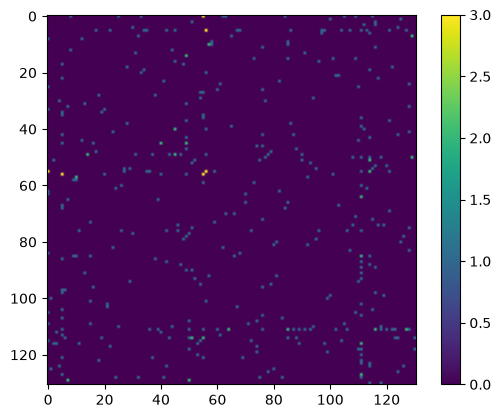

In [6]:
X_ij = calculate_co_occurence(reviews_clean, 1)
print(X_ij)

plt.imshow(X_ij.to_numpy())
plt.colorbar()
plt.show()

<span style="color: #E6E6E6;">
<span style="background-color: #545454; padding:8px; display:block; border-left:4px solid #4682b4">

### Exercise 2 - Loading GloVe vectors 

The Glove vectors we are going to use are located in a text file, where each line describes one word and its associated feature vector. Formatted as such: `word float float float ...`

If you do not already have the GloVe vectors, the first cell below downloads them for you (about 860MB, but you only have to do it once). The file `glove.6B.50d.txt` ends up in the same folder as this notebook. If you already have the file, put it in that folder and nothing will be downloaded.

#### **💻 2.1 Implement the `load_glove_vectors` function below, it should:**

1. Open the file a given glove file
2. Iterate across each line
3. Split the line into the word and the vector
    - Numpy's `np.asarray()` function can take a string containing numbers and put them in an array
4. Insert the word as a key in the dictionary and the vector as the value


#### **2.2 If we represented the GlOVe dictionary as one big matrix, what would its dimensionality be, and what would this mean?**

<span style="background-color: #00590D; padding:8px; display:block; border-left:4px solid #4682b4">

It would be $400000\times 50. The number of words times the dimensionality of each word-vector$

</span>




In [ ]:
def download_glove(filename="glove.6B.50d.txt"):
    """
    Downloads the GloVe vectors from Stanford and unzips the file we need, unless we already have it.
    There is nothing to implement here, just run the cell.
    """
    if os.path.exists(filename):
        print(f"{filename} is already here, so there is nothing to download")
        return

    # The zip file contains the vectors with 50, 100, 200 and 300 dimensions, but we only need the 50 dimensional ones
    urls = ["https://downloads.cs.stanford.edu/nlp/data/glove.6B.zip",
            "https://nlp.stanford.edu/data/glove.6B.zip"]
    zip_path = "glove.6B.zip"

    for url in urls:
        try:
            print(f"Downloading {url} (about 860MB, so this takes a few minutes)...")
            with urllib.request.urlopen(url, timeout=30) as response, open(zip_path, "wb") as f:
                total = response.headers.get("Content-Length")
                with tqdm(total=int(total) if total else None, unit="B", unit_scale=True) as progress:
                    while chunk := response.read(1024 * 1024):
                        f.write(chunk)
                        progress.update(len(chunk))
            break
        except OSError as error:
            print(f"Download failed ({error}), trying the next link...")
            if os.path.exists(zip_path):
                os.remove(zip_path)
    else:
        raise RuntimeError("Could not download the GloVe vectors. Download glove.6B.zip by hand from "
                           f"https://nlp.stanford.edu/projects/glove/ and put {filename} next to this notebook")

    with zipfile.ZipFile(zip_path) as z:
        z.extract(filename)
    os.remove(zip_path)
    print(f"Done, {filename} is ready")

download_glove()

In [28]:
def load_glove_vectors(glove_file_path):
    """

    """
    glove_dictionary = {}
    with open(glove_file_path,'r', encoding='utf-8') as file:
        for line in tqdm(file):
            elements = line.split()
            word = elements[0]
            vector = np.asarray(elements[1:],"float32")
            glove_dictionary[word] = vector
    
    return glove_dictionary

In [29]:
filename = "glove.6B.50d.txt"
glove_dictionary = load_glove_vectors(filename)

print(len(glove_dictionary), glove_dictionary["have"].shape)

400000it [00:03, 113343.70it/s]

400000 (50,)


<span style="color: #E6E6E6;">
<span style="background-color: #545454; padding:8px; display:block; border-left:4px solid #4682b4">


### Exercise 3 - Word similarities

In this exercise you will inspect the word embedding for different words, in order to determine whether words that semantically have similar meaning (or are semantically related) also have similar representations under the embedding.

To compare two words, we use the cosine similarity score between the feature vectors representing the two words.

#### **💻 3.1. Implement a function `cos_sim`, which computes the cosine similarity of two vectors: $\text{cosine\_similarity} = \frac{\vec{A} \cdot \vec{B}}{\|\vec{A}\| \|\vec{B}\|}$**

*Note that `scipy.spatial.distance.cosine` computes the cosine **distance**, which is $1 - \text{cosine\_similarity}$.*

#### **💻 3.2 Implement the function `word_similarity`, which computes the similarity of two words as strings.**

#### **3.3 Run the cells after two steps below, and compare the simliarity scores for each word pair within each group. You can use the following questions as guide for your answer:**

- Do the relative differences in scores reflect your own intuition? 
- Does this inform you about certain relations captured by the word embedding? 
- For instance, what can you learn from observing that 'Denmark' is more similar to 'Sweden' than to 'Copenhagen'?


<span style="background-color: #00590D; padding:8px; display:block; border-left:4px solid #4682b4">

Kinda, my intuition with words isn't really that good, but sometimes teh similarity may be a bit off. Why is brother and son so similar? Why is it more similar than daughter and sister?

Likewise, with prepositions, it may seem a bit arbritrary that left and right recieve less similarity than vertical and horizontal, though in this case, it may have to do with the fact that 'left' and 'right' is also used in politics or non-preposition related meanings.

Overall, we can go two ways; either try to make sense of it from a language perspective, or just accept that sometimes ML does weird things.

</span>

#### **3.4 What would be the similarity between the words "cat" and "cat"?**

<span style="background-color: #00590D; padding:8px; display:block; border-left:4px solid #4682b4">

1 - they're the same word, duh

</span>

</span>

In [9]:
def cos_sim(v1, v2):
    return 1 - spatial.distance.cosine(v1,v2)

def word_similarity(word1, word2, verbose=True):    
    v1 = glove_dictionary[word1]
    v2 = glove_dictionary[word2]
    similarity =  cos_sim(v1,v2)
    if verbose:
        print(f"Similarity score between {word1} and {word2} = {similarity:.3f}") 
    return similarity

In [10]:
#humans and family structures
word_similarity("king","queen")
word_similarity("prince","princess")
word_similarity("prince","brother")
word_similarity("princess","sister")
word_similarity("prince","sister")
word_similarity("princess","brother")
word_similarity("brother","sister")
word_similarity("brother","son")
word_similarity("sister","daughter")
word_similarity("brother","daughter")
word_similarity("sister","son")

Similarity score between king and queen = 0.784
Similarity score between prince and princess = 0.743
Similarity score between prince and brother = 0.759
Similarity score between princess and sister = 0.764
Similarity score between prince and sister = 0.591
Similarity score between princess and brother = 0.527
Similarity score between brother and sister = 0.725
Similarity score between brother and son = 0.945
Similarity score between sister and daughter = 0.893
Similarity score between brother and daughter = 0.827
Similarity score between sister and son = 0.750


0.750402304843057

In [11]:
#prepositions and orientations
word_similarity("after","before")
word_similarity("over","under")
word_similarity("vertical","horizontal")
word_similarity("left","right")

Similarity score between after and before = 0.951
Similarity score between over and under = 0.754
Similarity score between vertical and horizontal = 0.956
Similarity score between left and right = 0.781


0.781184383748652

In [12]:
#toponyms (places)
word_similarity("city","country")
word_similarity("city","town")
word_similarity("denmark","sweden")
word_similarity("denmark","copenhagen")
word_similarity("stockholm","copenhagen")
word_similarity("stockholm","denmark")
word_similarity("sweden","stockholm")
word_similarity("sweden","copenhagen")
word_similarity("walk","run")
word_similarity("run","sit")
word_similarity("walk","sit")

Similarity score between city and country = 0.667
Similarity score between city and town = 0.869
Similarity score between denmark and sweden = 0.885
Similarity score between denmark and copenhagen = 0.631
Similarity score between stockholm and copenhagen = 0.763
Similarity score between stockholm and denmark = 0.579
Similarity score between sweden and stockholm = 0.698
Similarity score between sweden and copenhagen = 0.573
Similarity score between walk and run = 0.683
Similarity score between run and sit = 0.539
Similarity score between walk and sit = 0.759


0.7587370613751933

In [13]:
#Homonyms (words with different meanings)
word_similarity("second","minute")
word_similarity("first","second")
word_similarity("first","minute")

Similarity score between second and minute = 0.720
Similarity score between first and second = 0.932
Similarity score between first and minute = 0.596


0.5956816559051554

<span style="color: #E6E6E6;">
<span style="background-color: #545454; padding:8px; display:block; border-left:4px solid #4682b4">

### Exercise 4: Nearest Neighbours

It can be pretty useful to find the $N$ nearest neighbours to a word, given the glove embedding.

#### **💻 4.1 Implement the function `nearest_neighbours` which computes the $N$ nearest neighbours (most similar words) to a single word. You can follow the steps as outlined below:**

1. Create an array containing all the vectors representations of every word and one for the vectors
         - `.keys()` provides an iterable of the keys of a dictionary
         - `.values()` does the same for the values, in the same order 
2. Compute the cosine similarity between the vector of the word and the vectors of all the words in the vocabulary
3. Find the top indices, and print the corresponding words and their similarity scores
    - A word is always the most similar to itself, make sure the word is not one of its own nearest neighbours 

#### **4.2 Look at the various words two steps below, do you agree that they are similar?**

<span style="background-color: #00590D; padding:8px; display:block; border-left:4px solid #4682b4">

I mean, I'm kinda chuffed that Sweden is more like Denmark than Norway, but otherwise, makes sense. You can also debate whether prince or queen is most similar, interesting to see whether gender or position is valued most, but that is a whole can of worms in ML

</span>

#### **4.3 Try to come up with some words that are dissimilar from any other What do you find?**


<span style="background-color: #00590D; padding:8px; display:block; border-left:4px solid #4682b4">

I thought I had a winner with "prestidigitation", but "high-brow" and "grandiloquence" are close to it, probably because, they like prestidigitation, are never really used. Grandiloquence especially means "pompous or extravagent langauge", which pretty well describes the kind of people who would seriously use prestidigitation (apart from D&D players). Overall, this is an example of not the meaning of the word, but when the word is used, being more relevant.

</span>

</span>

In [30]:
def nearest_neighbours(word, num_neighbours):    
    words = np.array(list(glove_dictionary.keys()))
    vectors = np.array(list(glove_dictionary.values()))
    
    # Compute cosine similarity between the target word vector and all vectors
    v = glove_dictionary[word]
    scores = np.dot(vectors, v) / (np.linalg.norm(vectors, axis=1) * np.linalg.norm(v))
    
    # A word is always the most similar to itself, so we exclude it
    scores[words == word] = -np.inf

    # Get indices of the top scores
    top_indices = np.argsort(scores)[-num_neighbours:][::-1]
    
    # Print the most similar words with their similarity scores
    print(f"Most similar words to '{word}':")
    for idx in top_indices:
        print(f"{scores[idx]:.4f}\t{words[idx]}")  

In [32]:
nearest_neighbours("denmark", 3)
nearest_neighbours("king", 3)

Most similar words to 'denmark':
0.8848	sweden
0.8509	norway
0.8200	austria
Most similar words to 'king':
0.8236	prince
0.7839	queen
0.7746	ii


<span style="color: #E6E6E6;">
<span style="background-color: #545454; padding:8px; display:block; border-left:4px solid #4682b4">


### Exercise 5 - Visualizing words using PCA

In this exercise we use principal component analysis (PCA) to reduce the dimensionality of the feature vector space. This allows us to illustrate the spatial relation between different words from the vocabulary.

#### **5.1. 💻 Implement the function, `plot_pca` that conducts PCA on a sub-set of the data and projects these data-points onto the first two principal components. You can follow these steps:** 
- Follow these steps:
    1. Obtain a matrix of the vectors and transpose it
    2. Subtract the mean of each dimension (axis=1) from the matrix
    3. Compute the eigenvectors and values of the covariance matrix
    4. Project the data onto the eigenvectors. Pay attention to the dimensions in order to do the projection correctly
    5. The eigenvectors are initially sorted in ascending order, take use the dimensions corresponding to the largest eigenvalues and plot them

#### **5.2 Comment on any linearity and distance between pairs of words.**

<span style="background-color: #00590D; padding:8px; display:block; border-left:4px solid #4682b4">

Not much to say, than they are linear, words that are similar have a linear relationship between them, at least in these two dimensions.

</span>

#### **5.3 When visualizing for many words, comment on which words are grouped together. Does the grouping capture any semantic meaning?**

<span style="background-color: #00590D; padding:8px; display:block; border-left:4px solid #4682b4">

Pretty much what has been mentioned before, but those with large similarity are grouped together.

Worth noting, is perhaps the distance may also mean something, meaning that the choice of cosine similarity may not be entirely cognisant, as it only takes into account angle between vectors.

</span>

In [16]:
def plot_pca(word_list):
    #obtain dictionary of words from word_list
    vectors = np.asarray([glove_dictionary[key] for key in word_list]).T
    
    #pca on feature vectors for selected words
    mean_vector = np.mean(vectors,axis=1)
    data = vectors - mean_vector[:,None]
    #compute the covariance matrix
    S = np.cov(data)
    #obtain eigenvectors and eigenvalues
    eigen_values, eigen_vectors = eigh(S)
    #sort according to size of eigenvalues
    Y = eigen_vectors.T @ (data)    # shape = (dim_vectors, num_words)
    #plot for first two principal components
    for label, x, y in zip(word_list, Y[-1,:], Y[-2,:]):
        plt.plot(x,y,"*")
        plt.annotate(label, xy=(x, y), xytext=(0, 0), textcoords='offset points')
    plt.show()

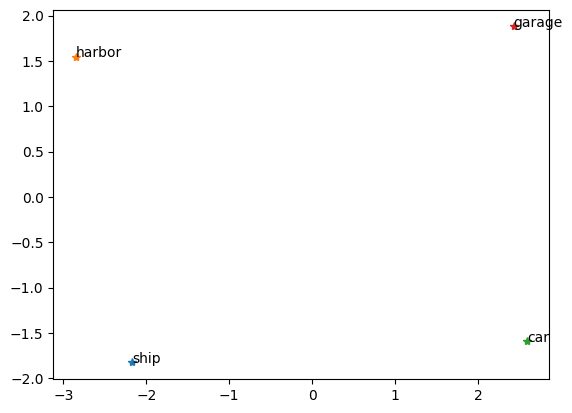

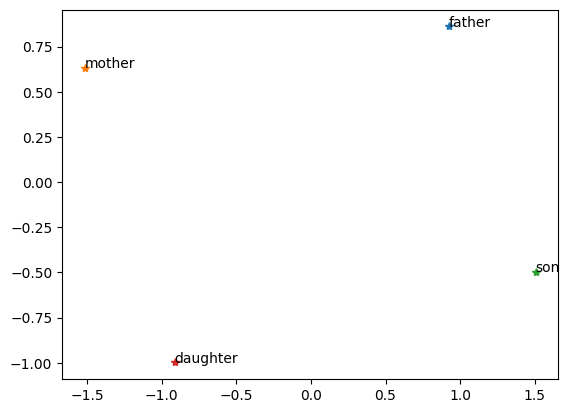

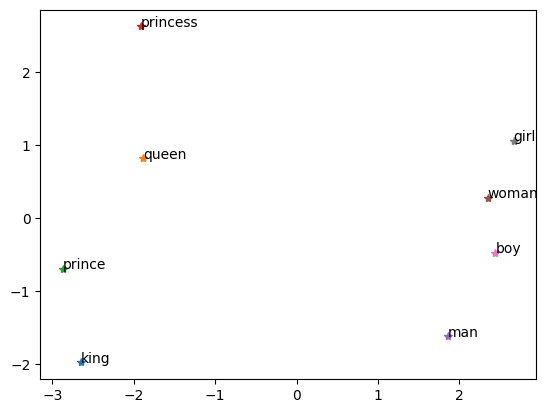

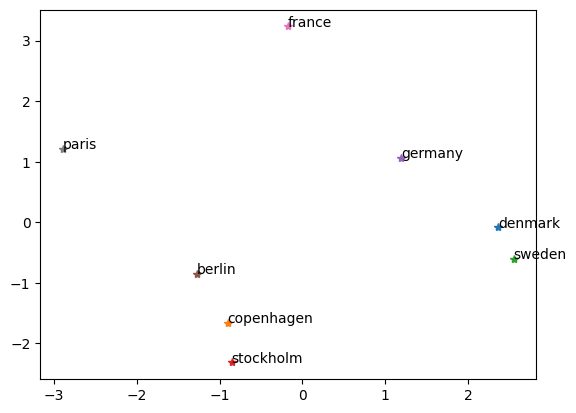

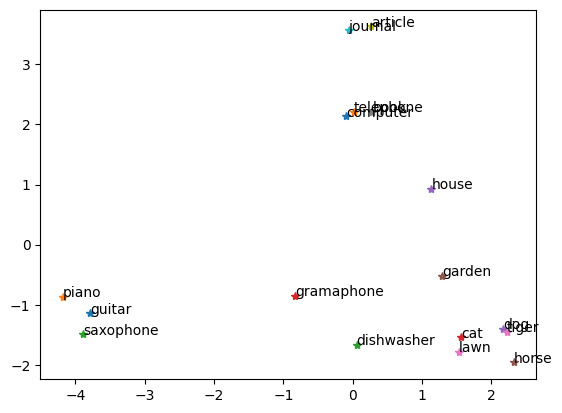

In [17]:
plot_pca(["ship","harbor","car","garage"])
plot_pca(["father","mother","son","daughter"])
plot_pca(["king","queen","prince","princess","man","woman","boy","girl"])
plot_pca(["denmark","copenhagen","sweden","stockholm","germany","berlin","france","paris"])
plot_pca(["guitar","piano","saxophone","cat","dog","horse","tiger","book","article","journal","computer","telephone","dishwasher","gramaphone","house","garden","lawn"])

<span style="color: #E6E6E6;">
<span style="background-color: #545454; padding:8px; display:block; border-left:4px solid #4682b4">

### Exercise 6 - Solving analogies
As defined by Aristotle as "an equality of proportions", an analogy can be considered a problem involving four terms, such that the second term is related to the first in a similar way as the forth term is related to the third.

An example of an analogy is;
- *evening* is to *morning* as *dinner* is to *breakfast*

Analogies are often used as verbal reasoning tests, where the test subject is asked to infer the similarity between two relations, by only being presented the first three terms of the analogy problem.
For instance, the subject is expected to infer the term *girl* from the problem;
- *brother* is to *sister* as *boy* is to *???*

These kind of problems are often included in assessments of intelligence (such as IQ or children development tests) as the ability to draw analogies are believed to reflect the underlying cognitive ability to represent and reason about higher-order relations.

In this exercise you are going to examine an AI algorithm for solving such analogy problems. As input, the algorithm is given the first three terms of an analogy problem. It will then rely on the linear substructure of the GloVe word embedding to find and return the best candidate word for the forth term.

**Algorithm:**
For a given problem, let $v_1,v_2,v_3$ be the vector representations for the first three terms. 
The guess for the forth term is found as the word for which the associated vector representation is most similar to the vector $v_d = (v_3 - (v_1-v_2))$. To compare vectors, the algorithm uses the cosine similarity measure.

#### **6.1. Argue why this approach is reasonable and why $v_d$ is computed as it is**

*Hint: It may be easier to build intuition from considering the problem in 2D.*

<span style="background-color: #00590D; padding:8px; display:block; border-left:4px solid #4682b4">

It's mostly smoke and mirrors, it can be rewritten as $v_d = v_3 + (v_2 - v_1)$, which is exactly our "king - man + woman = queen" question, which is what we really want to find. The rest of it is just cosine similarity, which we have done ad nauseam before.

</span>

#### **💻 6.2 Implement the function `find_analogy`, you can follow the following steps:**

- Follow these steps:
    1. Get the vector representations for each of the 3 words and calculate the fourth vector
    2. Create a matrix of word vectors that excludes the three original words 
    3. Calculate the cosine similarities to $v_d$
        - For this, use the given function `cos_sim_vec_mat` that calculates the cosine similarity between a vector and a matrix
    4. Return the `N` closest words and their scores
        - `np.argsort` sorts a vector in ascending order, `[::-1]` can be used to reverse the order of an array
        - To use the indexes on a list it must be converted to a numpy array

#### **6.3 Test the algorithm with the provided examples as well as with analogy problems of your own. Investigate whether there are particular types of analogies that the algorithm cannot solve. Comment on why this is.**

<span style="background-color: #00590D; padding:8px; display:block; border-left:4px solid #4682b4">

It works well when the relation is common and consistent in the text: gender and family (man:woman::king gives *queen*, woman:man::mother gives *father*), capitals (denmark:copenhagen::germany gives *berlin*, and france gives *paris*), opposites (left:right::horizontal gives *vertical*) and even a bit of grammar (france:french::denmark gives *danish*).

It struggles with:
- **Analogies without a real relation**, like pen:paper::doctor. The answers are just words close to *doctor* (*medical*, *working*, *worked*), since $v_2 - v_1$ doesn't add anything useful and $v_3$ dominates.
- **Words with several meanings**, since there is only one vector per word. france:paris::usa gives *austin* and *angeles*, and usa:washington::canada gives *states*, because *washington* is a person, a state and a city all at once.
- **Relations that aren't a constant offset**. apple:fruit::carrot gives *asparagus* and *marinated* instead of *vegetable*, and man:woman::uncle gives *daughter* and *niece* instead of *aunt*, since the "same" relation looks different for different pairs of words.

So the linear structure is only there for relations that are frequent enough in the data for GloVe to have "seen" them. On top of that, the algorithm always returns the closest vector, so it never says "this doesn't make sense".

</span>

#### **💻 6.4 For real cognitive tests the analogy problem is often presented as a multiple-choice question. Implement the function `find_analogy_multiple_choice` to present such a setting. Before you start, think on whether you would expect it to perform better or worse, and test it afterwards. The changes that need to be make programatically, are:**

 1. The function must take a list of words from which to choose 
 2. These must be used to create the matrix for calculating the similarities

<span style="background-color: #00590D; padding:8px; display:block; border-left:4px solid #4682b4">

I expected it to perform better (or at least not worse), and it does. Choosing between 4 words is a lot easier than choosing between 400000. If the right word is among the options, it can never rank lower than it did in the full vocabulary, since there are fewer words to beat. For the clear-cut examples (king, boy, germany, france, horizontal and mother) the answer is the same as before, and for car:parking::ship the full vocabulary prefers *berthing* (with *dock* second), while with the options *dock* wins.

The downside is that whoever writes the options does part of the work, and that the algorithm happily "answers" nonsense: pen:paper::doctor picks *patient* (0.67). The scores of the wrong options aren't low either (for man:woman::king, *father* gets 0.73 and *sister* 0.68, compared to 0.86 for *queen*), so it is the ranking, and not the size of the cosine similarity, that matters.

</span>


In [ ]:
def cos_sim_vec_mat(v1, v2):
    """Compute cosine similarity between a vector and a matrix."""
    # Normalize the vector v1
    v1_norm = v1 / np.linalg.norm(v1)

    # Normalize the matrix v2
    v2_norm = v2 / np.linalg.norm(v2, axis=1, keepdims=True)

    # Compute the cosine similarity
    similarity = np.dot(v2_norm, v1_norm)

    return similarity

def find_analogy(w1, w2, w3, N=1):
    # Retrieve vectors for the input words
    v1 = glove_dictionary[w1]
    v2 = glove_dictionary[w2]
    v3 = glove_dictionary[w3]
    
    # Calculate the analogy vector
    vd = v3 - (v1 - v2)
    
    # Create a list of words excluding w1, w2, w3
    words = list(glove_dictionary.keys())
    filtered_words = [word for word in words if word not in {w1, w2, w3}]
    
    # Get the vectors for the filtered words
    vectors = np.array([glove_dictionary[word] for word in filtered_words])

    # Calculate cosine similarities
    similarities = cos_sim_vec_mat(vd, vectors)
    
    # Find the index of the maximum similarity
    max_indexes = np.argsort(similarities)[-N:][::-1]
    
    # Return the corresponding word
    return np.array(filtered_words)[max_indexes], similarities[max_indexes]

man is to woman as doctor is to:
1: nurse: 0.842
2: child: 0.775
3: pregnant: 0.768
4: mother: 0.766
5: patient: 0.749


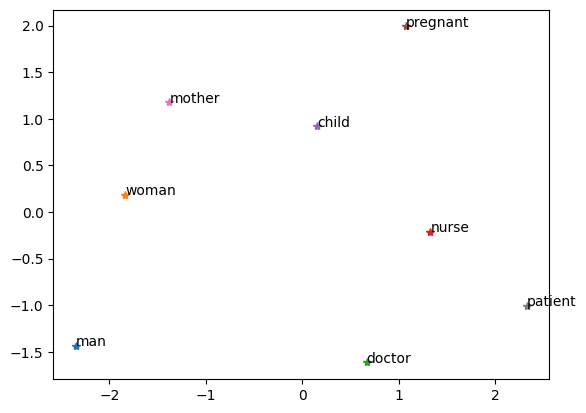

In [20]:
N = 5
#examples of analogy problems

#w1 = "man"; w2 = "woman"; w3 = "king";
#w1 = "brother"; w2 = "sister"; w3 = "boy";
#w1 = "pen"; w2 = "paper"; w3 = "doctor";
#w1 = "denmark"; w2 = "copenhagen"; w3 = "germany";
#w1 = "denmark"; w2 = "copenhagen"; w3 = "france";
#w1 = "denmark"; w2 = "france"; w3 = "copenhagen";
#w1 = "car"; w2 = "parking"; w3 = "ship";
#w1 = "left"; w2 = "right"; w3 = "horizontal";
#w1 = "woman"; w2 = "man"; w3 = "mother";
w1 = "man"; w2 = "woman"; w3 = "doctor";

w4, scores = find_analogy(w1, w2, w3, N)
print(w1, "is to", w2, "as", w3, "is to:")
for i, (word, score) in enumerate(zip(w4, scores)):
    print(f"{i+1}: {word}: {score:.3}")
plot_pca([w1,w2,w3,*w4])

In [21]:
def find_analogy_multiple_choice(w1, w2, w3, choices, N=1):
    # Retrieve vectors for the input words
    v1 = glove_dictionary[w1]
    v2 = glove_dictionary[w2]
    v3 = glove_dictionary[w3]
    
    # Calculate the analogy vector
    vd = v3 - (v1 - v2)
    # Get the vectors for the filtered words
    vectors = np.array([glove_dictionary[word] for word in choices])
    
    # Calculate cosine similarities
    similarities = cos_sim_vec_mat(vd, vectors)
    
    # Find the index of the maximum similarity
    max_indexes = np.argsort(similarities)[-N:][::-1]
    
    # Return the corresponding word
    return np.array(choices)[max_indexes], similarities[max_indexes]

man is to woman as doctor is to:
1: nurse: 0.842
2: teacher: 0.715
3: lawyer: 0.508
4: engineer: 0.415


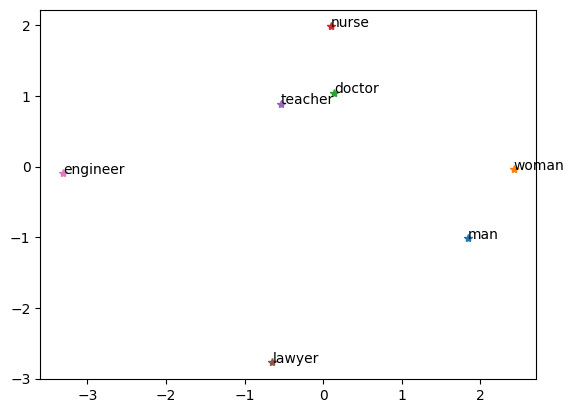

In [22]:
N = 4
# w1 = "man"; w2 = "woman"; w3 = "king"; options = ["queen", "prince", "father", "sister"]
# w1 = "brother"; w2 = "sister"; w3 = "boy"; options = ["girl", "man", "child", "parent"]
# w1 = "pen"; w2 = "paper"; w3 = "doctor"; options = ["stethoscope", "hospital", "patient", "nurse"]
# w1 = "denmark"; w2 = "copenhagen"; w3 = "germany"; options = ["berlin", "france", "sweden", "norway"]
# w1 = "denmark"; w2 = "copenhagen"; w3 = "france"; options = ["paris", "lyon", "marseille", "nice"]
# w1 = "denmark"; w2 = "france"; w3 = "copenhagen"; options = ["paris", "stockholm", "oslo", "helsinki"]
# w1 = "car"; w2 = "parking"; w3 = "ship"; options = ["dock", "garage", "boat", "plane"]
# w1 = "left"; w2 = "right"; w3 = "horizontal"; options = ["vertical", "diagonal", "up", "down"]
# w1 = "woman"; w2 = "man"; w3 = "mother"; options = ["father", "child", "sister", "parent"]
w1 = "man"; w2 = "woman"; w3 = "doctor"; options = ["nurse", "teacher", "engineer", "lawyer"]

w4, scores = find_analogy_multiple_choice(w1, w2, w3, choices=options, N=N)
print(w1, "is to", w2, "as", w3, "is to:")
for i, (word, score) in enumerate(zip(w4, scores)):
    print(f"{i+1}: {word}: {score:.3}")
plot_pca([w1,w2,w3,*w4])

<span style="color: #E6E6E6;">
<span style="background-color: #545454; padding:8px; display:block; border-left:4px solid #4682b4">


### Exercise 7 - Quantifying stereotypes

As for most machine learning algorithms, word embedding can be proned to biases. If the original data contained systematic biases, the learned representations may also reflect these biases. The GloVe machine learning algorithm was trained on Wikipedia texts. If these texts in general contained or described specific stereotypes, the word embedding will also capture these stereotypes. 
Often it is found that word embeddings contain gender stereotypes, often significantly with regards to professions.

#### **7.1. In the above exercises we have used the plot_pca function to visualize the words "nurse", "doctor", "man" and "woman". Comment on the plots in terms of gender stereotypes.**

<span style="background-color: #00590D; padding:8px; display:block; border-left:4px solid #4682b4">

The axes of a PCA plot are only defined up to a sign, so it is the relative positions that matter.

The first principal component (about 63% of the variance between these four words) mostly separates the professions (*doctor*, *nurse*) from the people (*man*, *woman*). The second (about 26%) separates *man* and *doctor* from *woman* and *nurse*. So the step from *man* to *woman* points in roughly the same direction as the step from *doctor* to *nurse*. In other words, the embedding has a "gender direction", and *nurse* sits on the female side of it while *doctor* sits on the male side.

The raw cosine similarities are a bit more nuanced. *Nurse* is clearly closer to *woman* (0.716) than to *man* (0.572), but *doctor* is about equally close to both (0.712 and 0.725). So the stereotype is much clearer for *nurse*, and *doctor* only looks "male" when it is compared to *nurse*.

</span>

#### **7.2 Compare the cosine similarity between various professions ("programmer", "secretary", "pilot", "president", "nurse",...) and the words "mother" and "father". Comment on your findings. The heatmap created in the first cell below shows these similarities.**

<span style="background-color: #00590D; padding:8px; display:block; border-left:4px solid #4682b4">

*Nurse* is the only one of the six professions that is closer to *mother* (0.72) than to *father* (0.59). *Engineer* (0.38 vs 0.56), *president* (0.41 vs 0.55) and *programmer* (0.21 vs 0.34) are all clearly closer to *father*, so for those the stereotype shows up.

It isn't quite that simple though. *Father* is closer than *mother* to most of the words I tried (12 out of 14, when I also added e.g. *doctor*, *lawyer*, *teacher* and *receptionist*), so the absolute numbers say little and it is the difference that counts. And *secretary*, the classic "female" job, is just as far on the *father* side as *programmer* (a difference of -0.13 for both). A likely reason is that *secretary* is also used for political titles like "secretary of state" (in the heatmap it is closest to *president*, 0.81, and the analogy solver gives *deputy*, *affairs* and *representative* for it), and GloVe only has one vector per word, so the meanings get mixed up.

</span>

#### **7.3 Evaluate terms that relate to the two words "man" and "woman" by comparing the nearest neighbours to "man" and "woman" respectively (the last two cells below print the 15 nearest neighbours of each). Are there any professions related to "man" and "woman"? Do "man" and "woman" have neighbours in common?**

<span style="background-color: #00590D; padding:8px; display:block; border-left:4px solid #4682b4">

There are no professions in the top 15 of either word. The neighbours of *woman* are mostly family and relationship words (*mother*, *wife*, *husband*, *grandmother*, *daughter*), pronouns (*her*, *she*, *herself*) and also *victim*. If we look at the top 50, *doctor*, *nurse* and *soldier* show up for *woman*, while *man* doesn't get any professions there.

The neighbours of *man* are mostly very generic words (*another*, *one*, *who*, *whose*, *a*, *turned*, *him*, *his*), the kind of words in sentences like "a man who...". Maybe *woman* is more often described through her relation to others, while *man* is the "default" person in the text.

They have *boy*, *old* and *she* in common (and each other, of course).

</span>

#### **7.4 Based on your findings, discuss whether you can use the analogy solver to test for various biases or stereotypes that may have been conveyed to the word embedding**

<span style="background-color: #00590D; padding:8px; display:block; border-left:4px solid #4682b4">

To some extent. man:woman::doctor gives *nurse* as the top answer (0.84), man:woman::chef gives *waitress*, *decorator*, *stylist* and *hairdresser*, man:woman::engineer gives *technician* and *mechanic*, and man:woman::programmer gives *therapist* and *psychotherapist*. In the other direction, woman:man::nurse gives *doctor*. These all fit the stereotypes.

But there are good reasons to be careful:
- A lot of the results aren't informative at all. *President* gives *met*, *presidency* and *vice*, and *secretary* gives *deputy* and *affairs*.
- The solver isn't allowed to return any of the three input words. If a profession was completely gender neutral, the "right" answer for man:woman::doctor would be *doctor* itself, but the function excludes it, so we can't see that.
- The offset $v_2 - v_1$ doesn't only contain gender. For *doctor* we also get *pregnant*, *mother* and *child*, which are about women and not about professions.
- We choose the words ourselves, and it is easy to pick the ones that look biased.

So the solver is nice for finding examples of bias, but I wouldn't use it to prove that there is none, or to measure how much there is.

</span>


#### **7.5. Reflect on whether word embedding in general is a feasible approach to verify if a text corpus contains biases or stereotypes.**

<span style="background-color: #00590D; padding:8px; display:block; border-left:4px solid #4682b4">

It is a nice first check, but not enough on its own.

It is cheap, it looks at the whole corpus at once instead of a few examples, and it can show associations nobody thought of looking for. We can also compare numbers (like the differences in similarity above) between different embeddings, or between corpora from different years.

But it has a number of problems:
- The embedding only reflects *co-occurrence*. *Nurse* being close to *woman* can be a stereotype in the text, but it can also just be the fact that most nurses are women. The embedding can't tell the difference between a text that describes the world and a text that is biased.
- It only tells us about the corpus it was trained on, and not which sentences caused the association.
- One vector per word means that words with several meanings get mixed up (*secretary*), and rare words get noisy vectors.
- We have to choose which words to test, and the result depends on that choice, as well as on the training settings (dimension, window size, etc.).
- Not finding any bias doesn't mean there is none.

So I'd use it to find out where to look, and then read the texts.

</span>

</span>


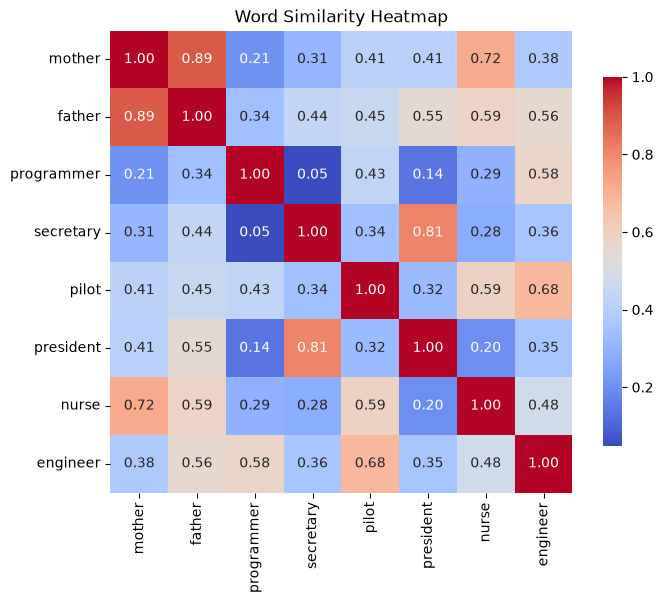

In [23]:
import seaborn as sns

# Define the words for which you want to compute similarities
words = ["mother", "father", "programmer", "secretary", "pilot", "president", "nurse", "engineer"]

# Create a similarity matrix
similarity_matrix = np.zeros((len(words), len(words)))

for i, word1 in enumerate(words):
    for j, word2 in enumerate(words):
        similarity_matrix[i, j] = word_similarity(word1, word2, verbose=False)

# Convert to DataFrame for better visualization
similarity_df = pd.DataFrame(similarity_matrix, index=words, columns=words)

# Create a heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(similarity_df, annot=True, cmap='coolwarm', fmt='.2f', square=True, cbar_kws={"shrink": .8})
plt.title('Word Similarity Heatmap')
plt.show()

In [24]:
nearest_neighbours("woman", 15)

Most similar words to 'woman':
0.9065	girl
0.8860	man
0.8764	mother
0.8613	her
0.8596	boy
0.8431	she
0.8225	herself
0.8108	child
0.8037	wife
0.7982	old
0.7976	victim
0.7936	husband
0.7868	person
0.7832	grandmother
0.7744	daughter


In [25]:
nearest_neighbours("man", 15)

Most similar words to 'man':
0.8860	woman
0.8564	boy
0.8453	another
0.8372	old
0.8276	one
0.8245	who
0.8195	him
0.8154	turned
0.8120	whose
0.8077	himself
0.8053	his
0.8051	a
0.7960	friend
0.7957	she
0.7954	young
